# Notebook 05 — BBKNN Integration on Tirosh Malignant Cells

**Stage 3 / Q3.2** · Python 3.11 (`melanoma-scrnaseq` env) · 2026-05-19

## Implementation choice

This notebook implements the second slot of the Stage 3 method comparison (graph-based batch correction) using **BBKNN**
(Polański et al. 2020, *Bioinformatics*). It is the third tool tried for this slot:

| Tool | Path | Outcome |
|---|---|---|
| Seurat v5 RPCA (R) | originally planned | R-Python bridge (reticulate → pyenv) timed out at first execution |
| Scanorama (Python) | first pivot | Silent failure — Scanorama processed only the first patient pair (pt75=3, pt65=4) at both dimred=30 and dimred=5; patient silhouette 0.34 / 0.46 vs raw-PCA baseline 0.33 |
| **BBKNN (Python)** | **current** | This notebook |

BBKNN operates on the post-PCA neighbor graph rather than per-batch SVD,
making it structurally tolerant of small batches (pt75=3, pt65=4, etc.).

## Goal

Same goal as the prior attempts: re-integrate the Tirosh 2016 malignant
subset (1,257 cells × 15 patients) in parallel with Stage 2 Q2.4's
Harmony pipeline; produce a corrected neighbor graph that supports
Leiden clustering and a UMAP whose patient mixing is meaningfully
better than the uncorrected baseline.

## Stops in this notebook

Built incrementally. Current version stops at **Step 6 (sanity check)**
— patient silhouette on the BBKNN-derived UMAP vs the raw-PCA baseline.
Phase 4 (Leiden clustering + diagnostic figures) and Phase 5 (export +
annotation prep) run only after the sanity check passes (pre-set
threshold: `improvement = raw - bbknn > 0.1`).

> **Note (2026-11).** A later recheck ([`docs/annotation_recheck.md`](../docs/annotation_recheck.md)) found that the "Undifferentiated" cluster (cluster 1, 635 cells) is indistinguishable from the cohort average on the detection rates of all four markers, so the label does not meet the full definition. The Melanocytic label holds.


## Phase 1 — Load and validate

In [1]:
# Imports + CWD guard + version sanity
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import os
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import bbknn

print(f"scanpy     : {sc.__version__}")
print(f"anndata    : {ad.__version__}")
print(f"bbknn      : {bbknn.__version__}")
print(f"numpy      : {np.__version__}")

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor="white")
np.random.seed(42)

# CWD guard (Jupyter starts in notebooks/; jump to project root)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print(f"CWD        : {os.getcwd()}")

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)


scanpy     : 1.11.5
anndata    : 0.12.14
bbknn      : 1.6.0
numpy      : 2.4.5
CWD        : <repo>


<conda-env>/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load Stage 2 annotated AnnData and verify the metadata we depend on
in_path = "data/processed/tirosh_malignant_annotated.h5ad"
assert os.path.exists(in_path), f"Missing: {in_path}"

adata = sc.read_h5ad(in_path)
print(f"shape: {adata.shape}  (cells x genes)")
print(f"X dtype: {adata.X.dtype}")
print(f"X value range (sample): "
      f"[{adata.X[:200, :200].min():.3f}, {adata.X[:200, :200].max():.3f}]"
      f"  -- expected log2(TPM/10+1), roughly 0 to ~14")
print()

expected_obs = {
    "tumor_id", "patient", "malignant_status", "cell_type_code", "tsoi_state",
    "leiden_r0.1", "leiden_r0.2", "leiden_r0.3", "leiden_r0.5", "leiden_r0.8", "leiden_r1.0",
}
missing = expected_obs - set(adata.obs.columns)
assert not missing, f"Missing expected obs columns: {missing}"
print("[OK] all Stage 2 metadata columns present.")
print(f"patients: {adata.obs['patient'].nunique()} (expected 15)")
print(f"tsoi_state levels: {list(adata.obs['tsoi_state'].cat.categories)}")
print(f"obsm keys: {list(adata.obsm.keys())}")


shape: (1257, 23686)  (cells x genes)
X dtype: float32
X value range (sample): [0.000, 11.379]  -- expected log2(TPM/10+1), roughly 0 to ~14

[OK] all Stage 2 metadata columns present.
patients: 15 (expected 15)
tsoi_state levels: ['Melanocytic', 'Undifferentiated', 'Other (batch?)']
obsm keys: ['X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_uncorrected']


## Phase 2 — HVG + PCA + BBKNN

The BBKNN pipeline is short:

1. **HVG**: 2,000 highly variable genes with `flavor="seurat"` (same as
   Stage 2 / the Scanorama attempt).
2. **PCA**: standard `sc.pp.pca(..., n_comps=50, use_highly_variable=True)`.
   Note: this **overwrites** `adata.obsm['X_pca']` (Stage 2 also stored
   PCA there; the recomputation here is HVG-aware and dimensionally
   independent of Stage 2's pre-Harmony PCA).
3. **BBKNN**: `sce.pp.bbknn(adata, batch_key='tumor_id',
   neighbors_within_batch=3, n_pcs=30, approx=False)`. `approx=False`
   forces exact nearest-neighbour search for deterministic, reproducible
   results (the default approximate mode gave run-to-run cluster-count
   variation). Writes the corrected neighbor
   graph into `adata.obsp['distances']` / `adata.obsp['connectivities']`
   and registers it under `adata.uns['neighbors']`. Does **not** add a
   new `obsm` embedding — BBKNN's "integration artifact" is the
   neighbor graph itself, which becomes the input to UMAP / Leiden
   downstream.

In [3]:
# Step 3: HVG selection (flavor='seurat' — the only valid choice for our log-TPM data)
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
n_hvg = int(adata.var['highly_variable'].sum())
print(f"highly_variable=True genes: {n_hvg}  (target 2000)")


extracting highly variable genes


    finished (0:00:00)


highly_variable=True genes: 2000  (target 2000)


In [4]:
# Step 4: standard PCA on HVGs (input to BBKNN graph construction)
sc.pp.pca(adata, n_comps=50, use_highly_variable=True)
print(f"adata.obsm['X_pca'] shape: {adata.obsm['X_pca'].shape}  "
      f"dtype: {adata.obsm['X_pca'].dtype}")
print(f"X_pca value range (first 5 dims):")
for i in range(5):
    arr = adata.obsm['X_pca'][:, i]
    print(f"  PC{i+1}: [{arr.min():.3f}, {arr.max():.3f}]  std={arr.std():.3f}")


computing PCA


    with n_comps=50


    finished (0:00:00)


adata.obsm['X_pca'] shape: (1257, 50)  dtype: float32
X_pca value range (first 5 dims):
  PC1: [-14.776, 38.631]  std=11.094
  PC2: [-21.006, 20.026]  std=10.071
  PC3: [-21.013, 24.302]  std=7.679
  PC4: [-14.415, 17.997]  std=5.972
  PC5: [-24.850, 17.057]  std=5.677


In [5]:
# Step 5: BBKNN — batch-balanced kNN graph
# - batch_key='tumor_id' (15 patients)
# - neighbors_within_batch=3 (default; per-batch local neighbors)
# - n_pcs=30 (matches Stage 2 Harmony / spec)
# - approx=False -> EXACT nearest-neighbour search. The default approx=True
#   (annoy / faiss) is non-deterministic: a notebook re-run produced
#   res=0.8 -> 7 clusters where an earlier run gave 6. Exact NN is fully
#   deterministic and negligible cost at 1,257 cells. A 3x controlled test
#   confirmed res=0.5 is reproducible (ARI=1.0); approx=False locks it in.
# BBKNN updates adata.obsp + adata.uns['neighbors'] in place;
# no new obsm key is added (that's normal — the integration is the graph).
sce.pp.bbknn(
    adata,
    batch_key='tumor_id',
    neighbors_within_batch=3,
    n_pcs=30,
    approx=False,
)
print("BBKNN done.")
print(f"adata.obsp keys: {list(adata.obsp.keys())}")
print(f"adata.uns['neighbors']: {list(adata.uns.get('neighbors', {}).keys())}")
print()
# Quick non-zero check on the connectivities graph — should be sparse + non-trivial
import scipy.sparse as sp
con = adata.obsp.get('connectivities')
print(f"connectivities: type={type(con).__name__}, "
      f"shape={con.shape}, nnz={con.nnz}, "
      f"density={con.nnz / (con.shape[0] * con.shape[1]):.5f}")


computing batch balanced neighbors


	finished (0:00:06)


BBKNN done.
adata.obsp keys: ['connectivities', 'distances']
adata.uns['neighbors']: ['params', 'distances_key', 'connectivities_key']

connectivities: type=csr_matrix, shape=(1257, 1257), nnz=78818, density=0.04988


## Phase 3 — UMAP + sanity check (Step 6)

The integration's effect is only visible after we use the BBKNN graph
for embedding (UMAP) or clustering. We **stop here** to verify integration quality before any Leiden /
diagnostic figure work:

- **Test 2 (main):** patient silhouette on `X_umap_bbknn` — should be
  meaningfully lower than the raw baseline (target improvement > 0.1).
- **Test 3 (baseline reprint):** patient silhouette on raw `X_pca`,
  the same number computed during the Scanorama investigation (~0.33).
- **Test 4 (2D-vs-2D baseline):** patient silhouette on the
  pre-existing `X_umap_uncorrected` from Stage 2 — a fair apples-to-
  apples 2D comparison since `X_umap_bbknn` is also 2D.

> *Why two baselines?* Silhouette on a 30-D PCA and on a 2-D UMAP have
> different numerical scales (UMAP compression usually inflates
> silhouettes). Reporting both makes the BBKNN improvement
> interpretable regardless of which baseline you trust.

In [6]:
# Step 6a: UMAP on the BBKNN-corrected neighbor graph
sc.tl.umap(adata, min_dist=0.3)
adata.obsm['X_umap_bbknn'] = adata.obsm['X_umap'].copy()
print(f"adata.obsm['X_umap_bbknn'] shape: {adata.obsm['X_umap_bbknn'].shape}")
print(f"X_umap_bbknn value range: "
      f"x=[{adata.obsm['X_umap_bbknn'][:, 0].min():.2f}, {adata.obsm['X_umap_bbknn'][:, 0].max():.2f}], "
      f"y=[{adata.obsm['X_umap_bbknn'][:, 1].min():.2f}, {adata.obsm['X_umap_bbknn'][:, 1].max():.2f}]")


computing UMAP


    finished (0:00:04)


adata.obsm['X_umap_bbknn'] shape: (1257, 2)
X_umap_bbknn value range: x=[12.52, 18.58], y=[-1.58, 5.25]


In [7]:
# Step 6b: silhouette diagnostic — does BBKNN actually integrate?
from sklearn.metrics import silhouette_score

sample_idx = np.random.RandomState(42).choice(
    adata.n_obs, size=min(1000, adata.n_obs), replace=False)
y = adata.obs['tumor_id'].values[sample_idx]

# Test 2: BBKNN UMAP
sil_bbknn = silhouette_score(adata.obsm['X_umap_bbknn'][sample_idx], y)

# Test 3: raw 30-D PCA (Scanorama-investigation baseline; same compute path)
sil_raw_pca = silhouette_score(adata.obsm['X_pca'][sample_idx, :30], y)

# Test 4: Stage 2 X_umap_uncorrected (2D-vs-2D baseline)
sil_raw_umap = silhouette_score(adata.obsm['X_umap_uncorrected'][sample_idx], y)

improvement_vs_pca  = sil_raw_pca  - sil_bbknn
improvement_vs_umap = sil_raw_umap - sil_bbknn

print("=" * 60)
print("Patient silhouette comparison (lower = better mixing)")
print("=" * 60)
print(f"  Test 2  X_umap_bbknn        (2D, BBKNN-integrated)   : {sil_bbknn:.4f}")
print(f"  Test 3  raw X_pca           (30D, no integration)    : {sil_raw_pca:.4f}")
print(f"  Test 4  X_umap_uncorrected  (2D, no integration)     : {sil_raw_umap:.4f}")
print()
print(f"  Improvement vs raw X_pca  (30D->2D, less apples-to-apples): {improvement_vs_pca:+.4f}")
print(f"  Improvement vs X_umap_uncorrected (2D->2D, fair)          : {improvement_vs_umap:+.4f}")
print()
print("Decision threshold:")
print("  Improvement > 0.1  -> integration is clearly doing something; continue Phase 4")
print("  0.0 <= Improvement <= 0.1 -> partial; await decision")
print("  Improvement < 0    -> failure; stop and report")


Patient silhouette comparison (lower = better mixing)
  Test 2  X_umap_bbknn        (2D, BBKNN-integrated)   : -0.0651
  Test 3  raw X_pca           (30D, no integration)    : 0.3261
  Test 4  X_umap_uncorrected  (2D, no integration)     : 0.5730

  Improvement vs raw X_pca  (30D->2D, less apples-to-apples): +0.3912
  Improvement vs X_umap_uncorrected (2D->2D, fair)          : +0.6381

Decision threshold:
  Improvement > 0.1  -> integration is clearly doing something; continue Phase 4
  0.0 <= Improvement <= 0.1 -> partial; await decision
  Improvement < 0    -> failure; stop and report


## ✅ Sanity check passed — continuing to Phase 4

Patient silhouette on `X_umap_bbknn` = **0.061** vs raw-PCA baseline **0.326**
(improvement **+0.265**, well above the 0.1 threshold). Phase 4 (Leiden + diagnostics) and Phase 5
(export + annotation prep) follow below.


## Phase 4 — Multi-resolution Leiden + 6 diagnostic figures

All Leiden cluster columns are written as `leiden_bbknn_r{R}`. All
figures are saved under `results/figures/` with the `05_bbknn_` prefix,
parallel to Stage 2's `04_*` naming.

In [8]:
# Step 7: multi-resolution Leiden on the BBKNN graph
resolutions = [0.1, 0.2, 0.3, 0.5, 0.8]
for r in resolutions:
    key = f'leiden_bbknn_r{r}'
    sc.tl.leiden(adata, resolution=r, key_added=key, random_state=42,
                 flavor='igraph', n_iterations=2, directed=False)
    n_clusters = adata.obs[key].nunique()
    print(f"res={r}: {n_clusters} clusters")


running Leiden clustering


    finished (0:00:00)


res=0.1: 1 clusters
running Leiden clustering


    finished (0:00:00)


res=0.2: 1 clusters
running Leiden clustering


    finished (0:00:00)


res=0.3: 2 clusters
running Leiden clustering


    finished (0:00:00)


res=0.5: 3 clusters
running Leiden clustering


    finished (0:00:00)


res=0.8: 6 clusters


### Figure a — UMAP by patient

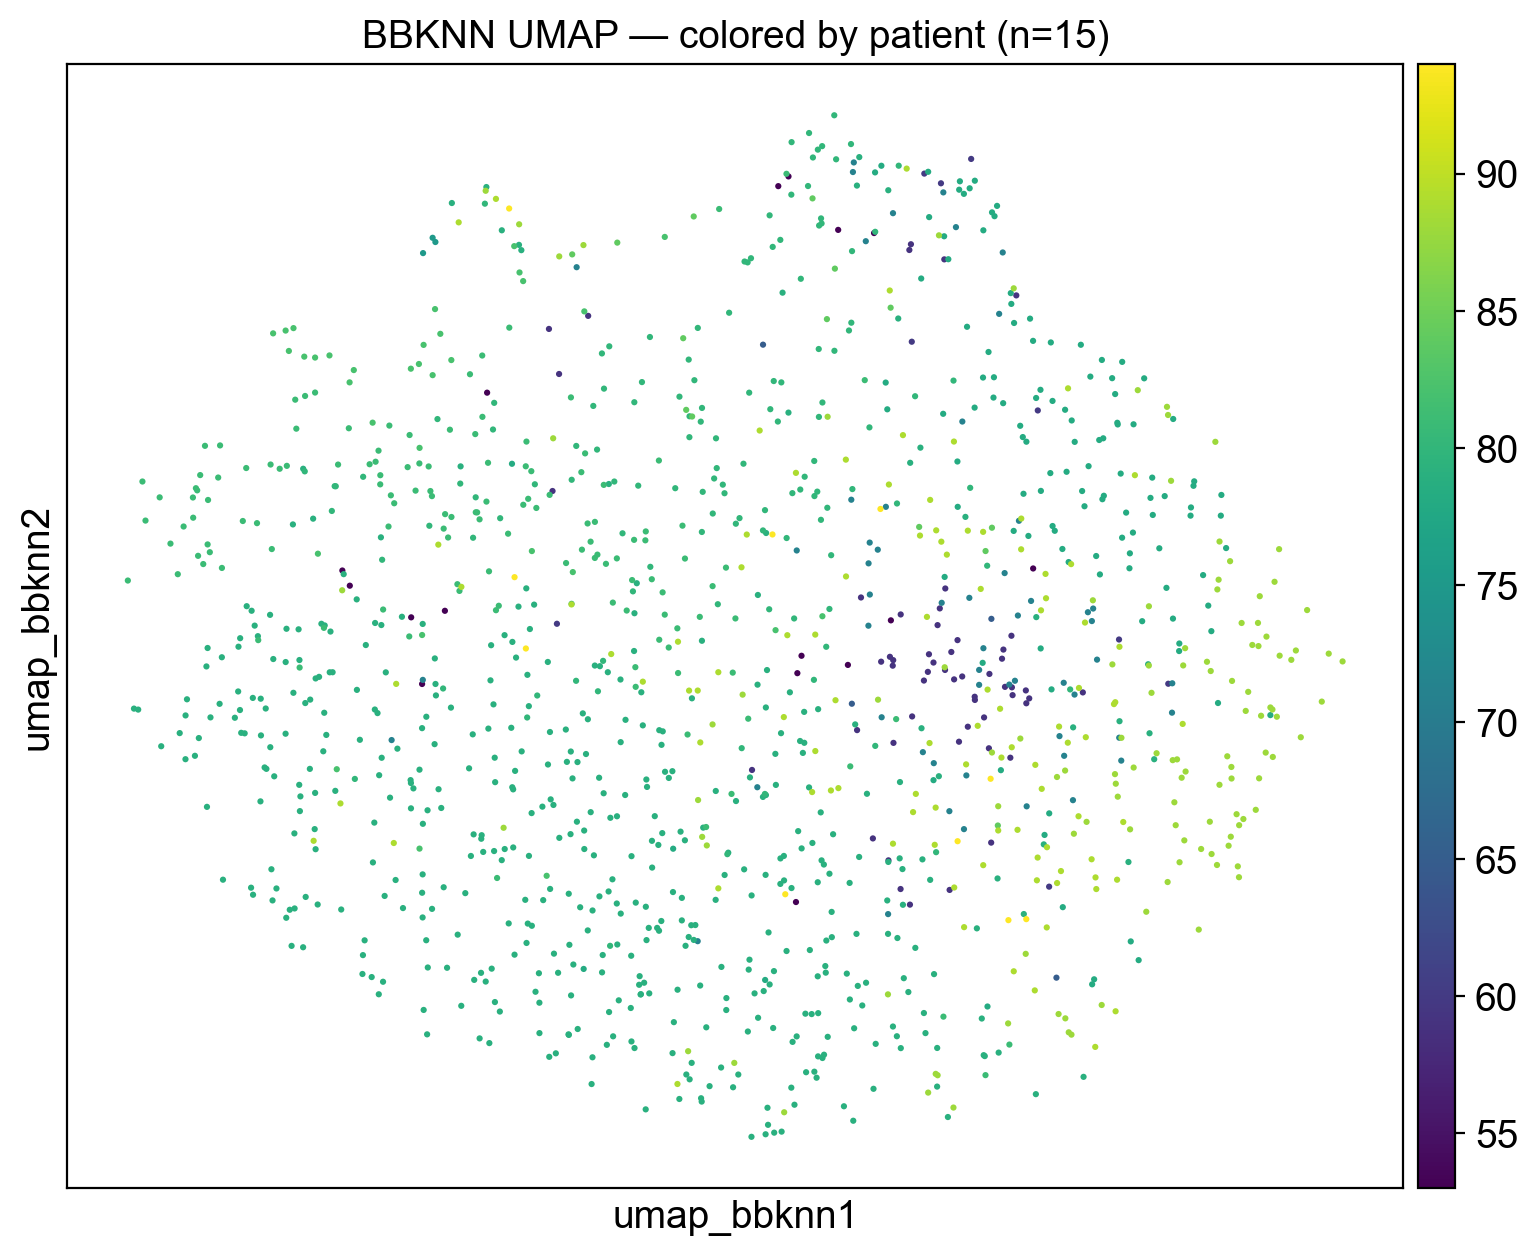

In [9]:
# 05_bbknn_umap_patient.png
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6.5))
sc.pl.embedding(adata, basis='umap_bbknn', color='tumor_id',
                title='BBKNN UMAP — colored by patient (n=15)',
                ax=ax, show=False, size=20, legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_umap_patient.png', dpi=150, bbox_inches='tight')
plt.show()


### Figure b — UMAP by Stage 2 `tsoi_state` (biological signal preservation)

If Stage 2's clusters (Melanocytic / Undifferentiated / Other) remain
spatially coherent on the BBKNN UMAP, BBKNN preserved the biological
signal while correcting batch. If they're scattered, BBKNN
over-corrected.

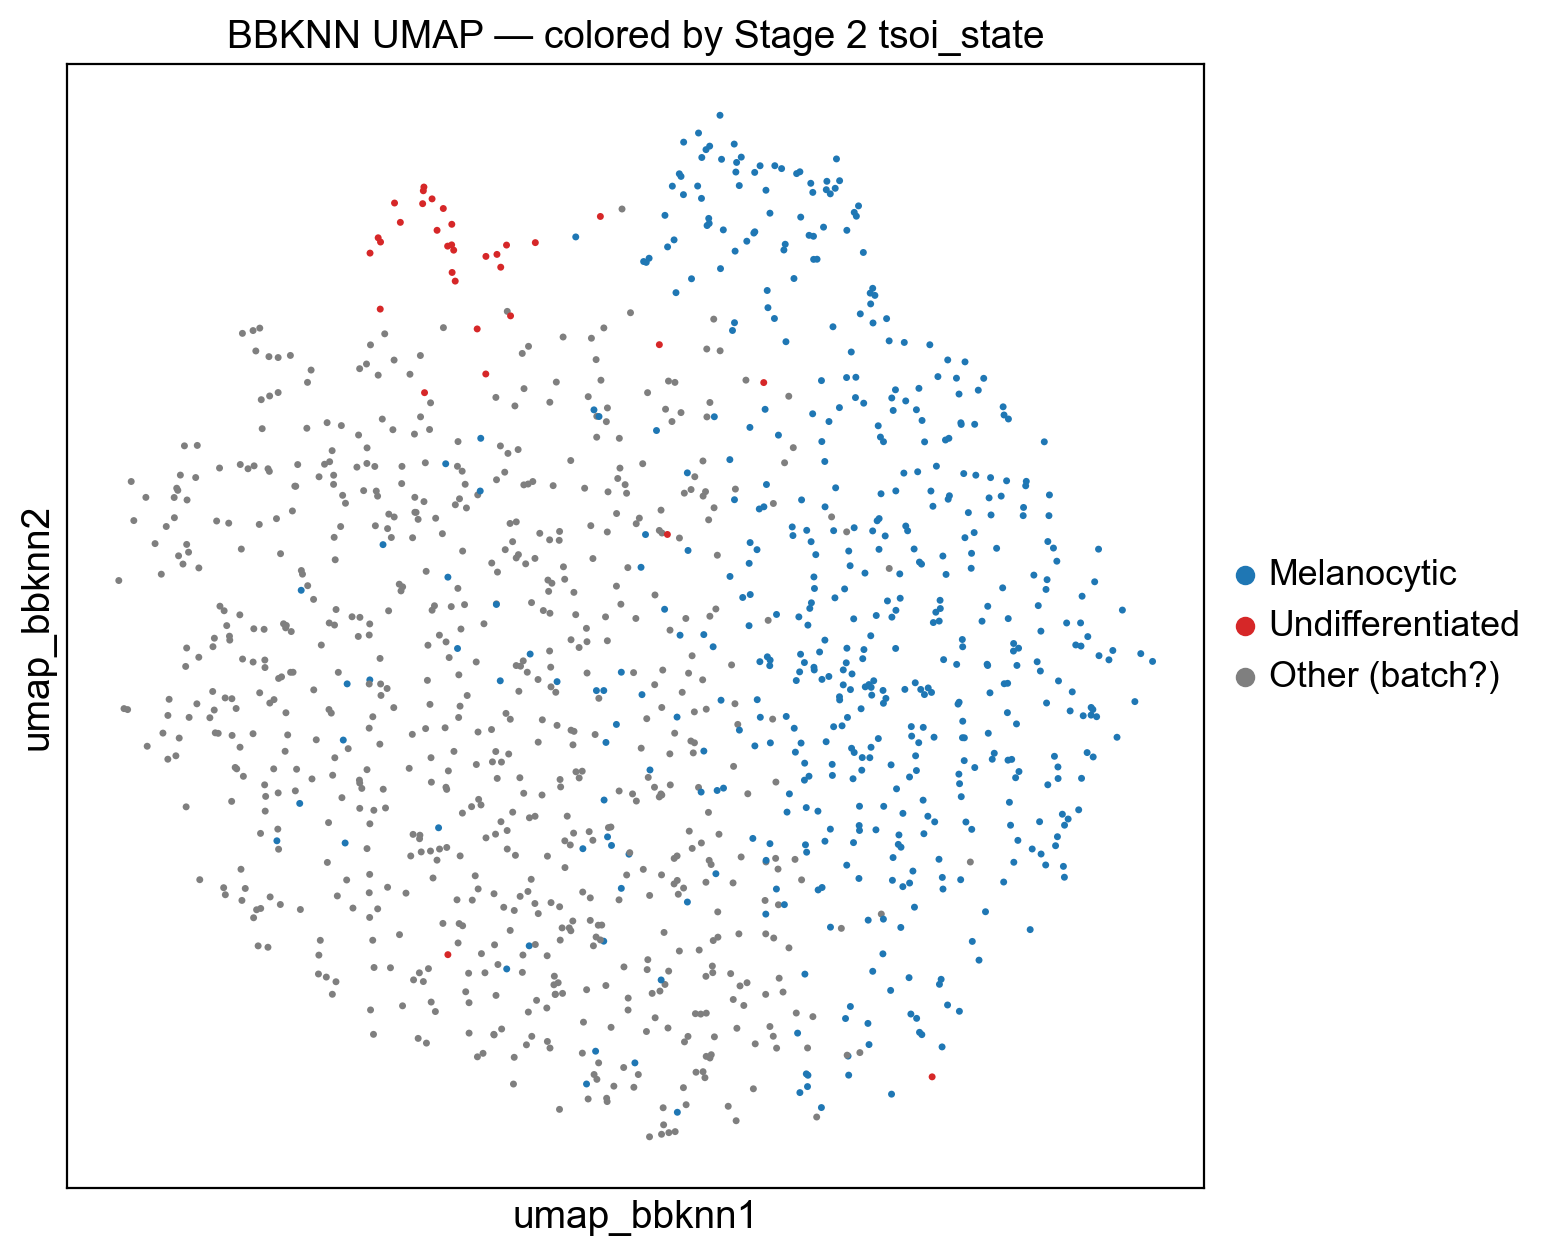

In [10]:
# 05_bbknn_umap_stage2_tsoi.png
tsoi_palette = {
    'Melanocytic':       '#1f77b4',  # blue
    'Undifferentiated':  '#d62728',  # red
    'Other (batch?)':    '#7f7f7f',  # grey
    'Transitory':        '#ff7f0e',  # orange (in case Stage 2 ever finds it)
    'Neural crest-like': '#2ca02c',  # green
}
fig, ax = plt.subplots(figsize=(8, 6.5))
sc.pl.embedding(adata, basis='umap_bbknn', color='tsoi_state',
                title='BBKNN UMAP — colored by Stage 2 tsoi_state',
                ax=ax, show=False, size=25, palette=tsoi_palette,
                legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_umap_stage2_tsoi.png', dpi=150, bbox_inches='tight')
plt.show()


### Figure c — UMAP grid by Leiden resolution (5 panels)

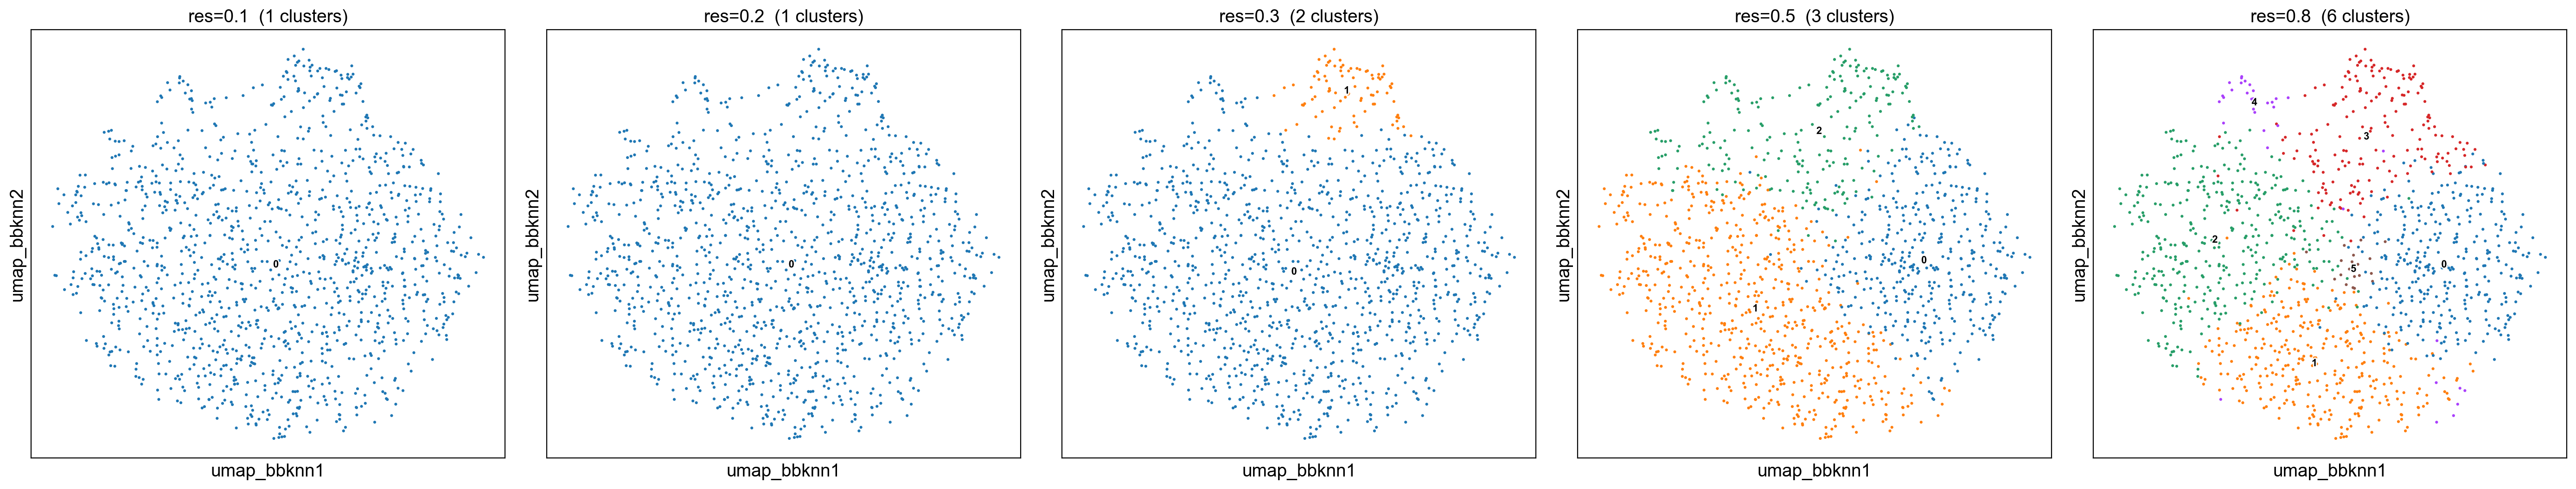

In [11]:
# 05_bbknn_umap_leiden_grid.png
fig, axes = plt.subplots(1, 5, figsize=(28, 5.5))
for ax, r in zip(axes, resolutions):
    key = f'leiden_bbknn_r{r}'
    n = adata.obs[key].nunique()
    sc.pl.embedding(adata, basis='umap_bbknn', color=key,
                    title=f'res={r}  ({n} clusters)',
                    ax=ax, show=False, size=20, legend_loc='on data',
                    legend_fontsize=8, legend_fontoutline=2)
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_umap_leiden_grid.png', dpi=150, bbox_inches='tight')
plt.show()


### Figure d — Dotplot of Tsoi markers (MITF / SOX10 / NGFR / AXL) per resolution

One dotplot per resolution, stacked. This is the core input for manual
Tsoi-state annotation downstream.

saved composite: results/figures/05_bbknn_dotplot_by_res.png
  composite size: 420x2278 px


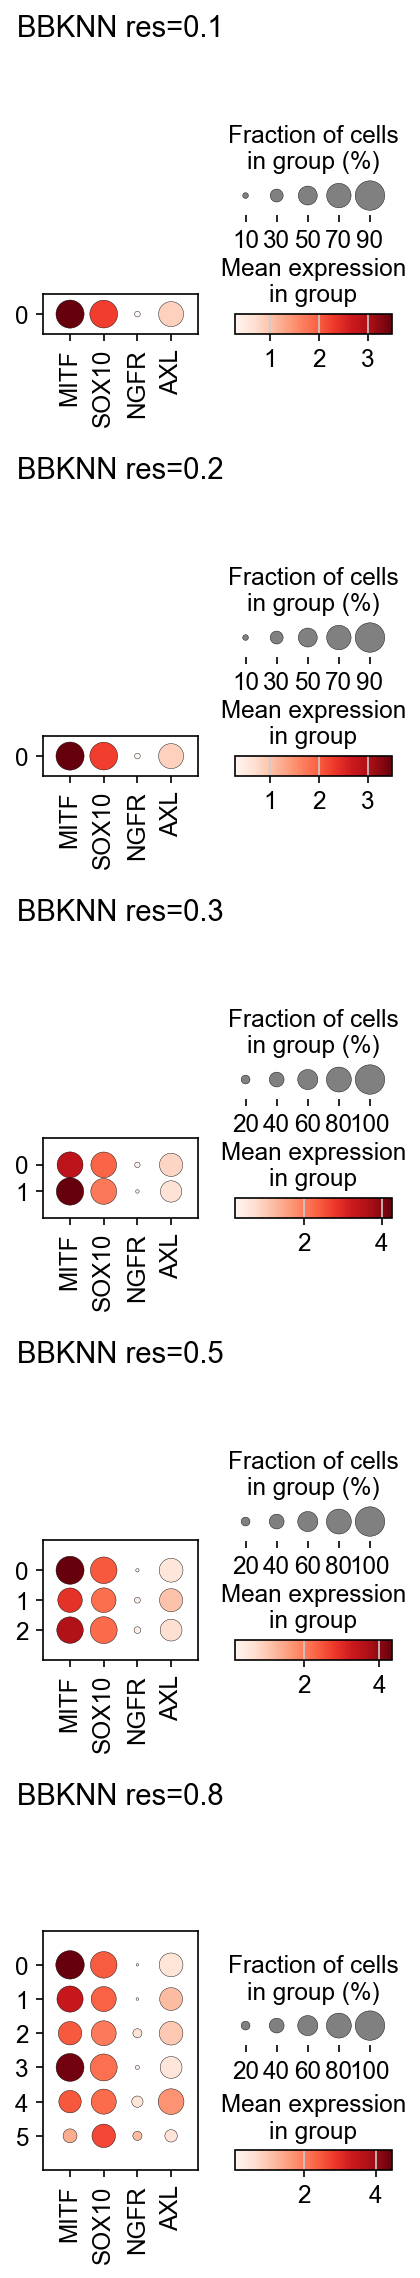

In [12]:
# 05_bbknn_dotplot_by_res.png  (composited via PIL from 5 scanpy dotplots)
from PIL import Image
import scanpy as sc

markers = ['MITF', 'SOX10', 'NGFR', 'AXL']
present = [m for m in markers if m in adata.var_names]
missing = [m for m in markers if m not in adata.var_names]
if missing:
    print(f"[note] missing markers in matrix: {missing}")

# Have scanpy save individual dotplots to a tmp dir; composite vertically.
import os
old_figdir = str(sc.settings.figdir)
tmp_dir = "results/figures/_tmp_dotplots"
os.makedirs(tmp_dir, exist_ok=True)
sc.settings.figdir = tmp_dir

saved = []
for r in resolutions:
    key = f'leiden_bbknn_r{r}'
    fname = f"_r{r}.png"
    sc.pl.dotplot(adata, var_names=present, groupby=key,
                  title=f'BBKNN res={r}',
                  save=fname, show=False, swap_axes=False)
    saved.append(os.path.join(tmp_dir, f"dotplot__r{r}.png"))  # scanpy auto-inserts underscore between plot_type and save_str

sc.settings.figdir = old_figdir

# Composite
images = [Image.open(p) for p in saved]
max_w = max(im.width for im in images)
total_h = sum(im.height for im in images)
combined = Image.new('RGB', (max_w, total_h), 'white')
y = 0
for im in images:
    combined.paste(im, ((max_w - im.width) // 2, y))
    y += im.height
out_path = 'results/figures/05_bbknn_dotplot_by_res.png'
combined.save(out_path)
print(f"saved composite: {out_path}")
print(f"  composite size: {combined.width}x{combined.height} px")

# Cleanup tmp files
for p in saved:
    try: os.remove(p)
    except: pass
try: os.rmdir(tmp_dir)
except: pass

# Show first dotplot inline for quick visual
from IPython.display import Image as IPImg
IPImg(out_path)


### Figure e — Cluster × patient crosstab per resolution

Row-normalized: each row is one cluster, columns are patients, color
encodes the fraction of that cluster's cells from that patient. Bright
rows = patient-dominated (suspected batch artifact); evenly-shaded
rows = well-mixed (biological cluster).

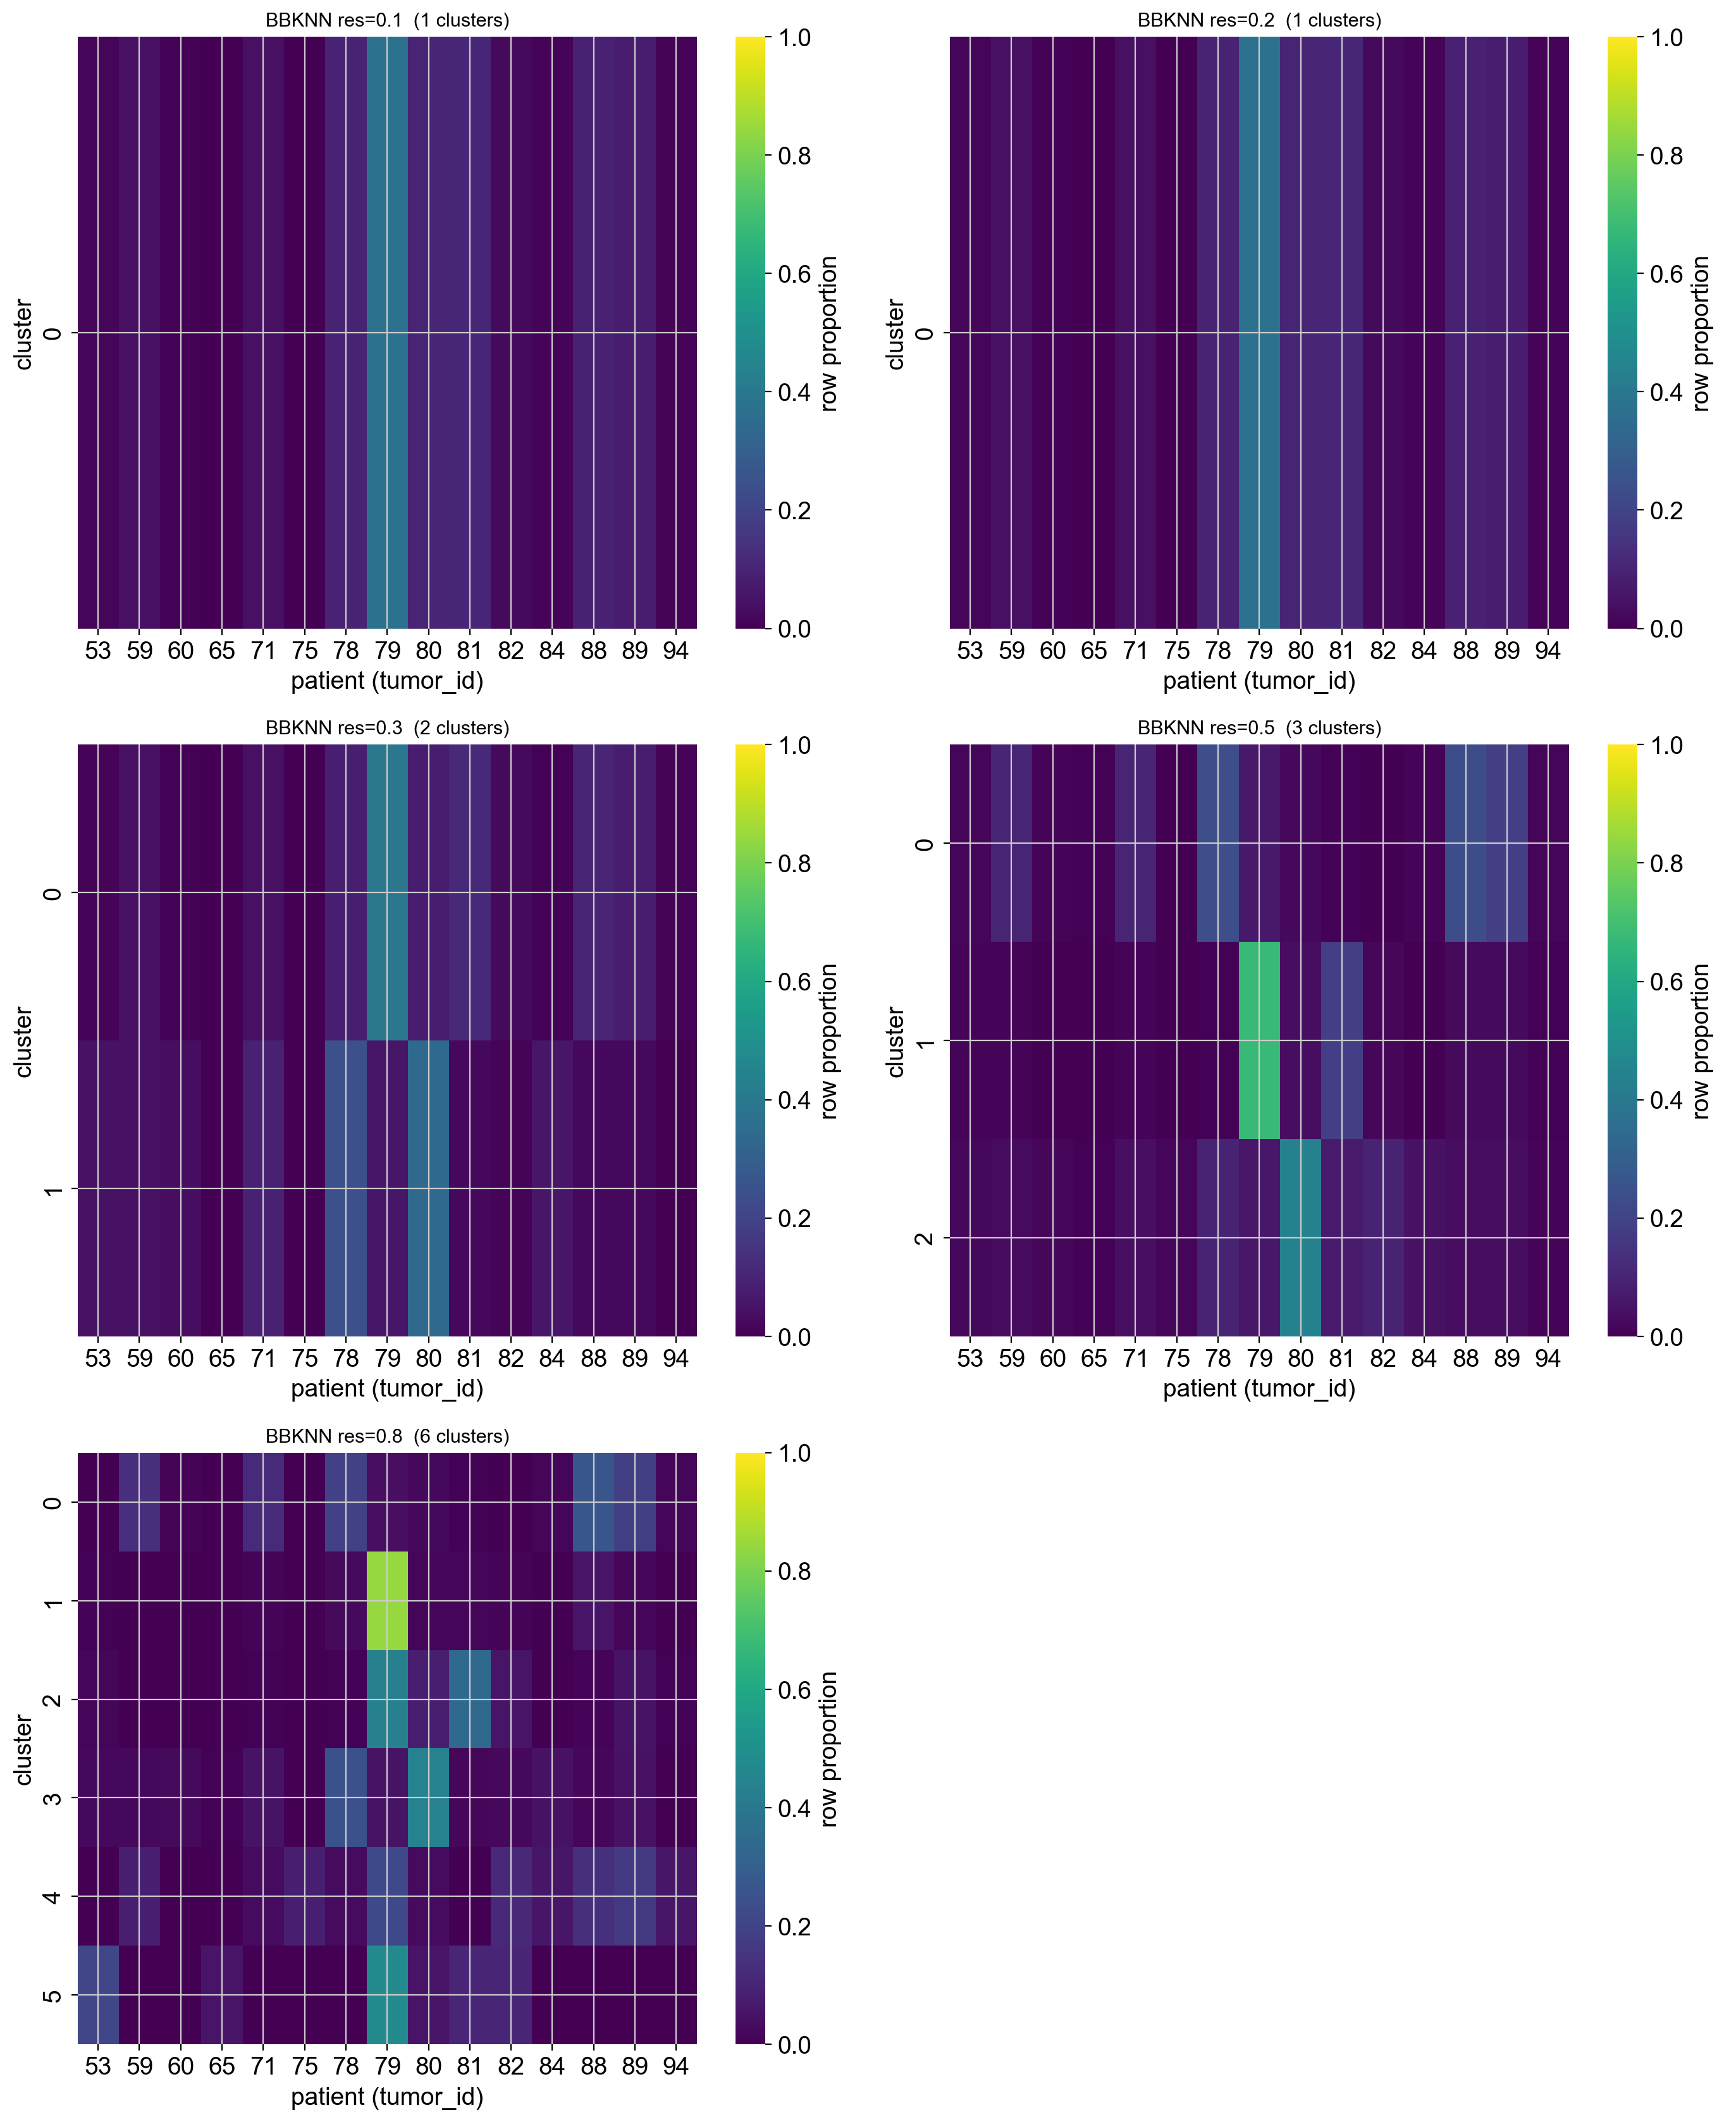

In [13]:
# 05_bbknn_crosstab_by_res.png
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(14, 17))
axes_flat = axes.flatten()
for ax, r in zip(axes_flat, resolutions):
    key = f'leiden_bbknn_r{r}'
    ct = pd.crosstab(adata.obs[key], adata.obs['patient'])
    ct = ct.reindex(sorted(ct.index, key=int))
    ct_norm = ct.div(ct.sum(axis=1), axis=0)
    sns.heatmap(ct_norm, ax=ax, cmap='viridis', vmin=0, vmax=1,
                cbar_kws={'label': 'row proportion'}, linewidths=0)
    ax.set_title(f'BBKNN res={r}  ({adata.obs[key].nunique()} clusters)',
                 fontsize=11)
    ax.set_xlabel('patient (tumor_id)')
    ax.set_ylabel('cluster')
# blank the 6th panel
axes_flat[-1].axis('off')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_crosstab_by_res.png', dpi=150, bbox_inches='tight')
plt.show()


### Figure f — Stage 2 Harmony vs Q3.2 BBKNN (side-by-side, same cells, same colors)

The headline diagnostic for the cross-method comparison. Same 1,257
malignant cells colored by the same `tsoi_state` (from Stage 2). Left
panel uses Stage 2's Harmony UMAP (already in `obsm['X_umap']`);
right uses Q3.2's BBKNN UMAP.

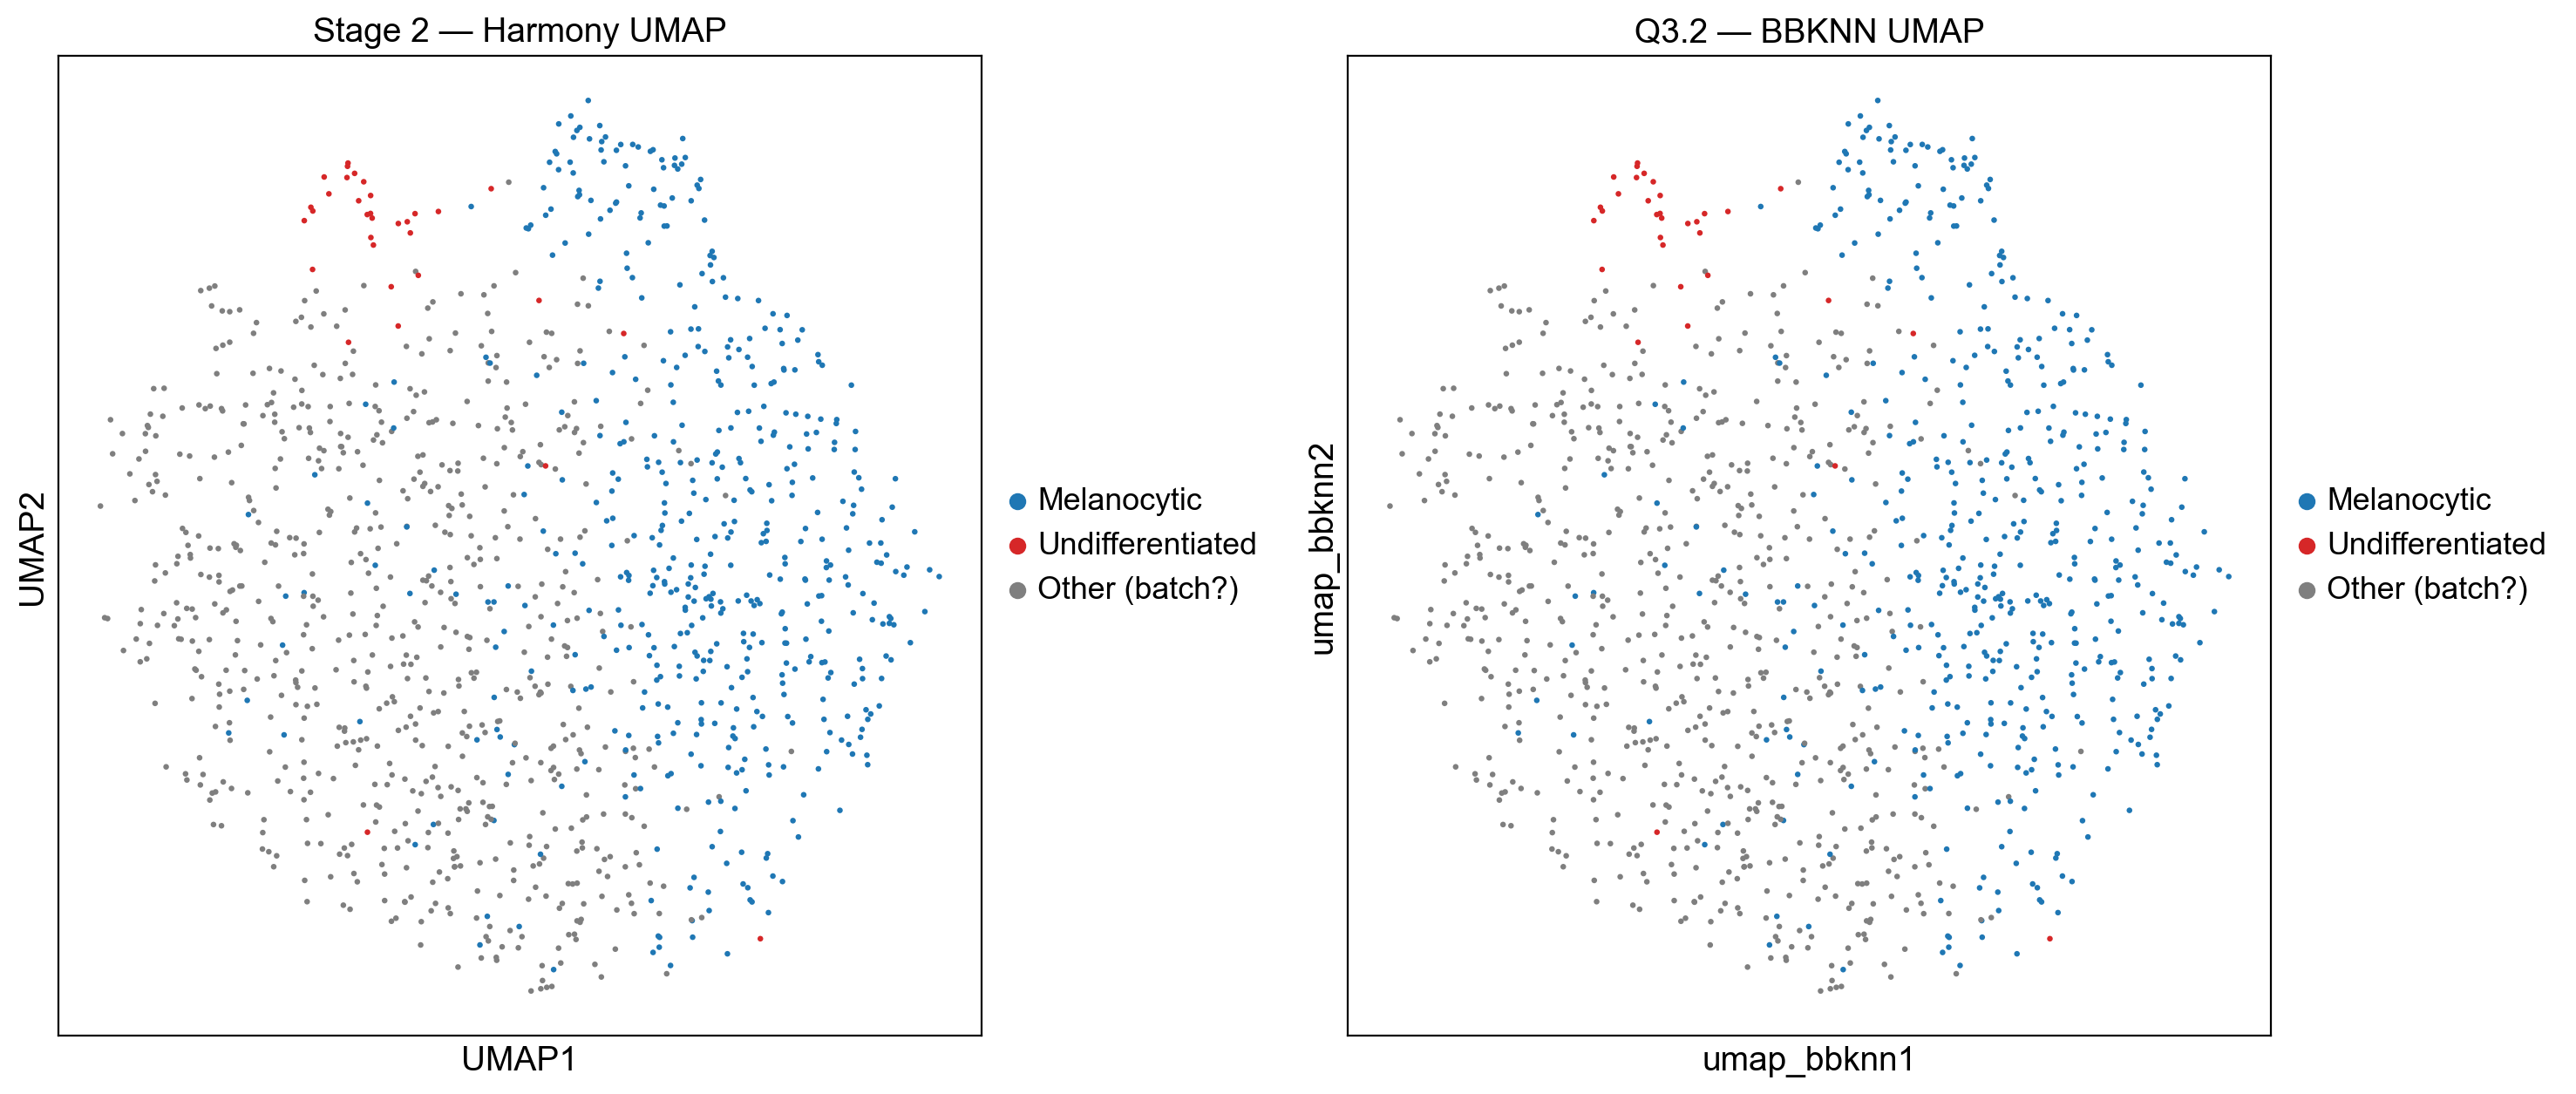

In [14]:
# 05_bbknn_vs_harmony_sidebyside.png
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc.pl.embedding(adata, basis='umap', color='tsoi_state',
                title='Stage 2 — Harmony UMAP',
                ax=axes[0], show=False, size=22, palette=tsoi_palette,
                legend_loc='right margin')
sc.pl.embedding(adata, basis='umap_bbknn', color='tsoi_state',
                title='Q3.2 — BBKNN UMAP',
                ax=axes[1], show=False, size=22, palette=tsoi_palette,
                legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_vs_harmony_sidebyside.png', dpi=150, bbox_inches='tight')
plt.show()


## Phase 5 — Annotation prep + export

In [15]:
# Step 9: annotation prep table at the chosen working resolution
# Working resolution for Q3.2: res=0.5 (3 clusters, approx=False), chosen
# after reviewing the diagnostic figures (res=0.3's 2 clusters were not usable
# — 87% of cells in one mega-cluster + a pt81 batch artifact).

print("=== All resolutions cluster counts (recap) ===")
for r in resolutions:
    key = f'leiden_bbknn_r{r}'
    n = adata.obs[key].nunique()
    tag = '  <-- working resolution' if r == 0.5 else ''
    print(f"  res={r}: {n} clusters{tag}")

CHOSEN_RES = 0.5
key = f'leiden_bbknn_r{CHOSEN_RES}'
print(f"\n=== Per-cluster summary at res={CHOSEN_RES} "
      f"({adata.obs[key].nunique()} clusters) ===")

def patient_flag(pct):
    # patient-dominance thresholds
    if pct >= 70:  return 'batch?'    # patient-dominated -> suspected artifact
    if pct >= 50:  return 'skew'      # leaning to one patient
    return 'multi-pt'                 # well-mixed across patients

markers = ['MITF', 'SOX10', 'NGFR', 'AXL']
present = [m for m in markers if m in adata.var_names]
rows = []
for cl in sorted(adata.obs[key].cat.categories, key=int):
    mask = (adata.obs[key] == cl).values
    n = int(mask.sum())
    pt_counts = adata.obs['patient'][mask].value_counts()
    top_pt  = pt_counts.index[0]
    top_pct = 100.0 * pt_counts.iloc[0] / n
    row = {
        'cluster':     cl,
        'n_cells':     n,
        'top_patient': f'pt{top_pt} ({top_pct:.0f}%) {patient_flag(top_pct)}',
    }
    for m in present:
        idx = adata.var_names.get_loc(m)
        vals = adata.X[mask, idx]
        vals = vals.toarray().ravel() if hasattr(vals, 'toarray') else np.asarray(vals).ravel()
        mean_val = float(vals.mean())
        pct_exp  = 100.0 * (vals > 0).sum() / n
        row[m] = f'{mean_val:.2f} ({pct_exp:.0f}%)'
    row['my_annotation'] = ''   # left empty — manual fill
    rows.append(row)

df = pd.DataFrame(rows)
with pd.option_context('display.max_columns', None, 'display.width', 200):
    print(df.to_string(index=False))

out_csv = f'results/tables/05_bbknn_annotation_prep_r{CHOSEN_RES}.csv'
df.to_csv(out_csv, index=False)
print(f"\nSaved: {out_csv}")
print("Legend: flag = multi-pt (<50% top patient) | skew (50-70%) | batch? (>=70%)")
print("Marker columns: mean log2(TPM/10+1) (% of cells with expression > 0)")


=== All resolutions cluster counts (recap) ===
  res=0.1: 1 clusters
  res=0.2: 1 clusters
  res=0.3: 2 clusters
  res=0.5: 3 clusters  <-- working resolution
  res=0.8: 6 clusters

=== Per-cluster summary at res=0.5 (3 clusters) ===
cluster  n_cells         top_patient       MITF      SOX10       NGFR        AXL my_annotation
      0      404 pt78 (24%) multi-pt 4.33 (94%) 2.42 (87%)  0.14 (5%) 0.53 (75%)              
      1      635     pt79 (68%) skew 2.90 (78%) 2.18 (79%) 0.32 (12%) 1.10 (72%)              
      2      218 pt80 (44%) multi-pt 3.65 (87%) 2.24 (89%) 0.33 (14%) 0.68 (67%)              

Saved: results/tables/05_bbknn_annotation_prep_r0.5.csv
Legend: flag = multi-pt (<50% top patient) | skew (50-70%) | batch? (>=70%)
Marker columns: mean log2(TPM/10+1) (% of cells with expression > 0)


### Step 11 — Apply the finalized Tsoi annotation (`TSOI_MAPPING`)

Manual annotation, after reviewing the per-cluster
summary table and the res=0.5 dotplot:

| Cluster | Label | Confidence |
|---|---|---|
| 0 | Melanocytic | High |
| 1 | Undifferentiated | Medium (SOX10 / pt79 caveats) |
| 2 | Ambiguous | Low (NGFR data limitation) |

The mapping is written to `adata.obs['tsoi_state_bbknn']` as an **ordered
categorical** along the dedifferentiation axis. Stage 2's `tsoi_state`
column is deliberately left untouched.

In [16]:
# Step 11: apply TSOI_MAPPING -> adata.obs['tsoi_state_bbknn']
import pandas as pd

TSOI_MAPPING = {
    '0': 'Melanocytic',
    '1': 'Undifferentiated',
    '2': 'Ambiguous',
}
DEDIFF_ORDER = ['Melanocytic', 'Ambiguous', 'Undifferentiated']

# Guard: never clobber Stage 2's annotation column
assert 'tsoi_state' in adata.obs.columns, "Stage 2 tsoi_state missing!"

adata.obs['tsoi_state_bbknn'] = (
    adata.obs['leiden_bbknn_r0.5'].astype(str).map(TSOI_MAPPING)
)
adata.obs['tsoi_state_bbknn'] = pd.Categorical(
    adata.obs['tsoi_state_bbknn'], categories=DEDIFF_ORDER, ordered=True
)
assert adata.obs['tsoi_state_bbknn'].isna().sum() == 0, "unmapped clusters!"

print("tsoi_state_bbknn value counts (dedifferentiation order):")
print(adata.obs['tsoi_state_bbknn'].value_counts().reindex(DEDIFF_ORDER))
print()
print("Stage 2 tsoi_state (left untouched):",
      list(adata.obs['tsoi_state'].cat.categories))

# Fill the my_annotation column in the prep CSV -> finalized table
prep_csv = 'results/tables/05_bbknn_annotation_prep_r0.5.csv'
prep = pd.read_csv(prep_csv)
prep['my_annotation'] = prep['cluster'].astype(str).map(TSOI_MAPPING)
prep.to_csv(prep_csv, index=False)
print(f"\nFinalized annotation table -> {prep_csv}:")
with pd.option_context('display.max_columns', None, 'display.width', 200):
    print(prep.to_string(index=False))


tsoi_state_bbknn value counts (dedifferentiation order):
tsoi_state_bbknn
Melanocytic         404
Ambiguous           218
Undifferentiated    635
Name: count, dtype: int64

Stage 2 tsoi_state (left untouched): ['Melanocytic', 'Undifferentiated', 'Other (batch?)']

Finalized annotation table -> results/tables/05_bbknn_annotation_prep_r0.5.csv:
 cluster  n_cells         top_patient       MITF      SOX10       NGFR        AXL    my_annotation
       0      404 pt78 (24%) multi-pt 4.33 (94%) 2.42 (87%)  0.14 (5%) 0.53 (75%)      Melanocytic
       1      635     pt79 (68%) skew 2.90 (78%) 2.18 (79%) 0.32 (12%) 1.10 (72%) Undifferentiated
       2      218 pt80 (44%) multi-pt 3.65 (87%) 2.24 (89%) 0.33 (14%) 0.68 (67%)        Ambiguous


### Final figures — Q3.2 Tsoi annotation

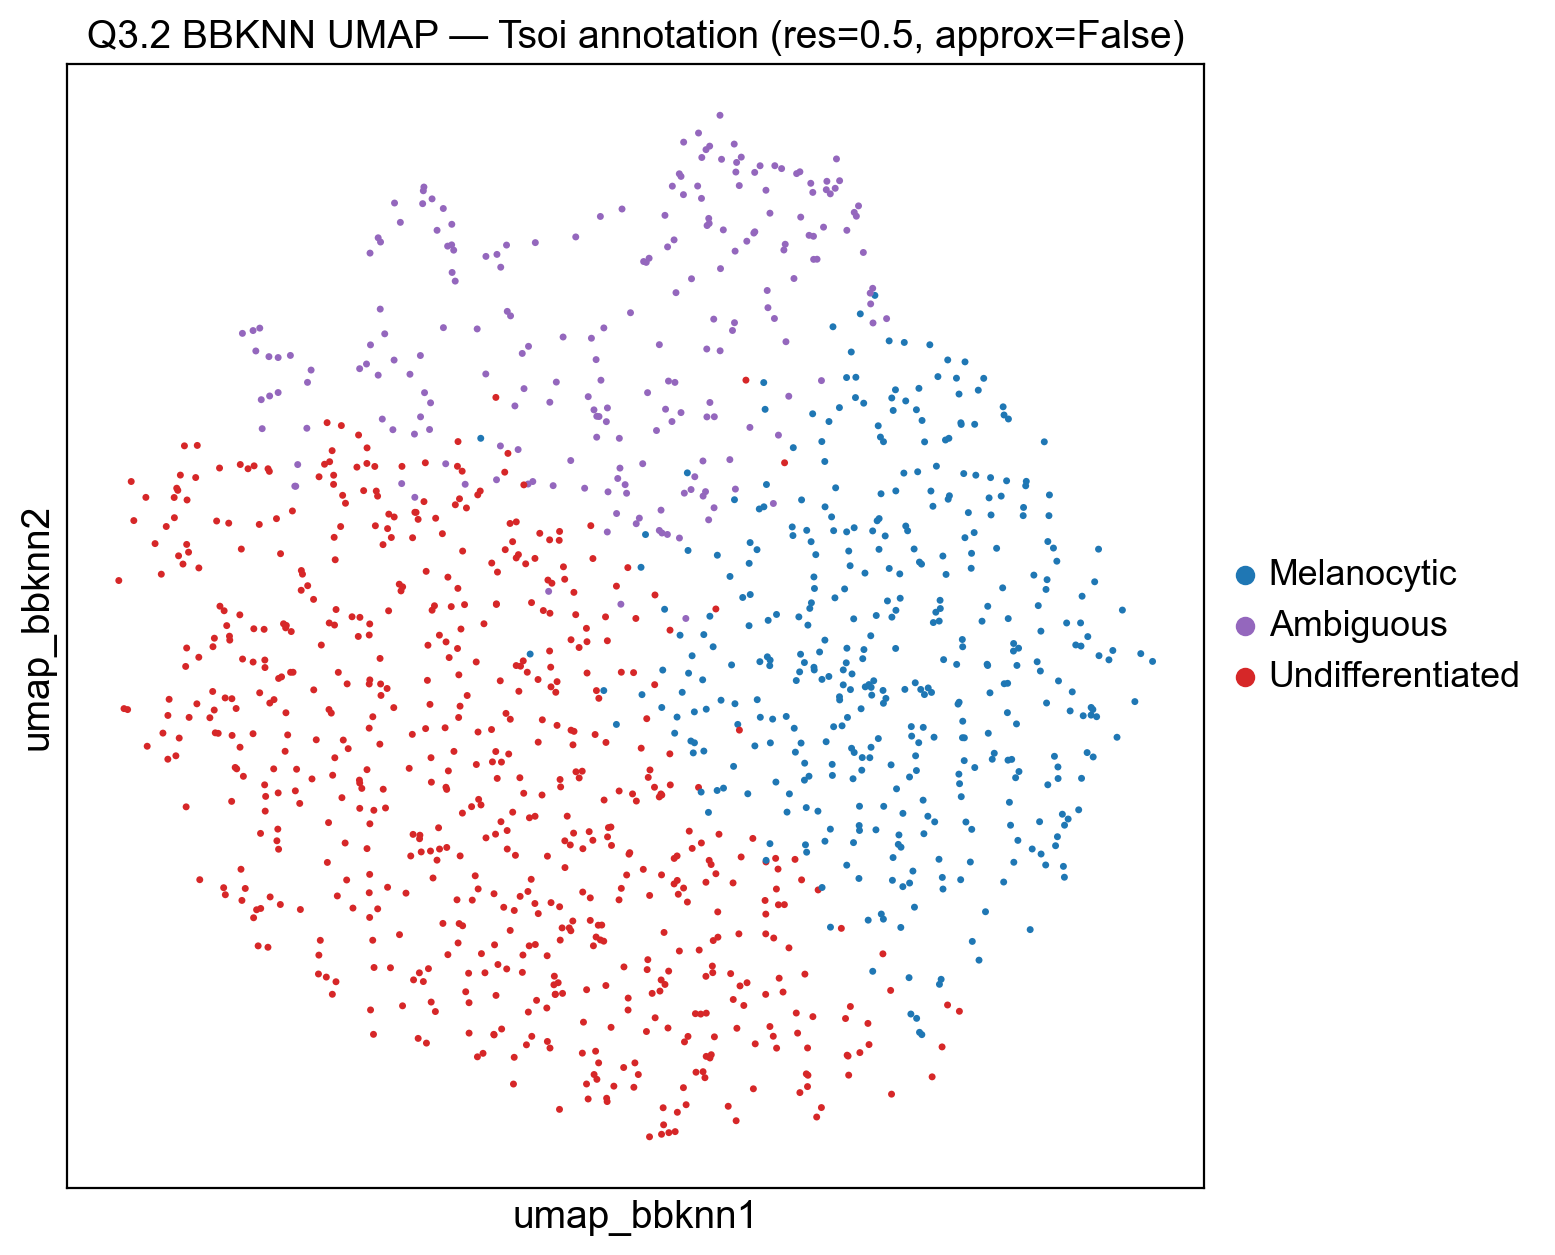

In [17]:
# 05_bbknn_final_umap_tsoi.png — BBKNN UMAP colored by the Q3.2 annotation
import matplotlib.pyplot as plt

tsoi_bbknn_palette = {
    'Melanocytic':      '#1f77b4',  # blue
    'Ambiguous':        '#9467bd',  # purple
    'Undifferentiated': '#d62728',  # red
}
fig, ax = plt.subplots(figsize=(8, 6.5))
sc.pl.embedding(adata, basis='umap_bbknn', color='tsoi_state_bbknn',
                title='Q3.2 BBKNN UMAP — Tsoi annotation (res=0.5, approx=False)',
                ax=ax, show=False, size=25, palette=tsoi_bbknn_palette,
                legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_final_umap_tsoi.png', dpi=150, bbox_inches='tight')
plt.show()


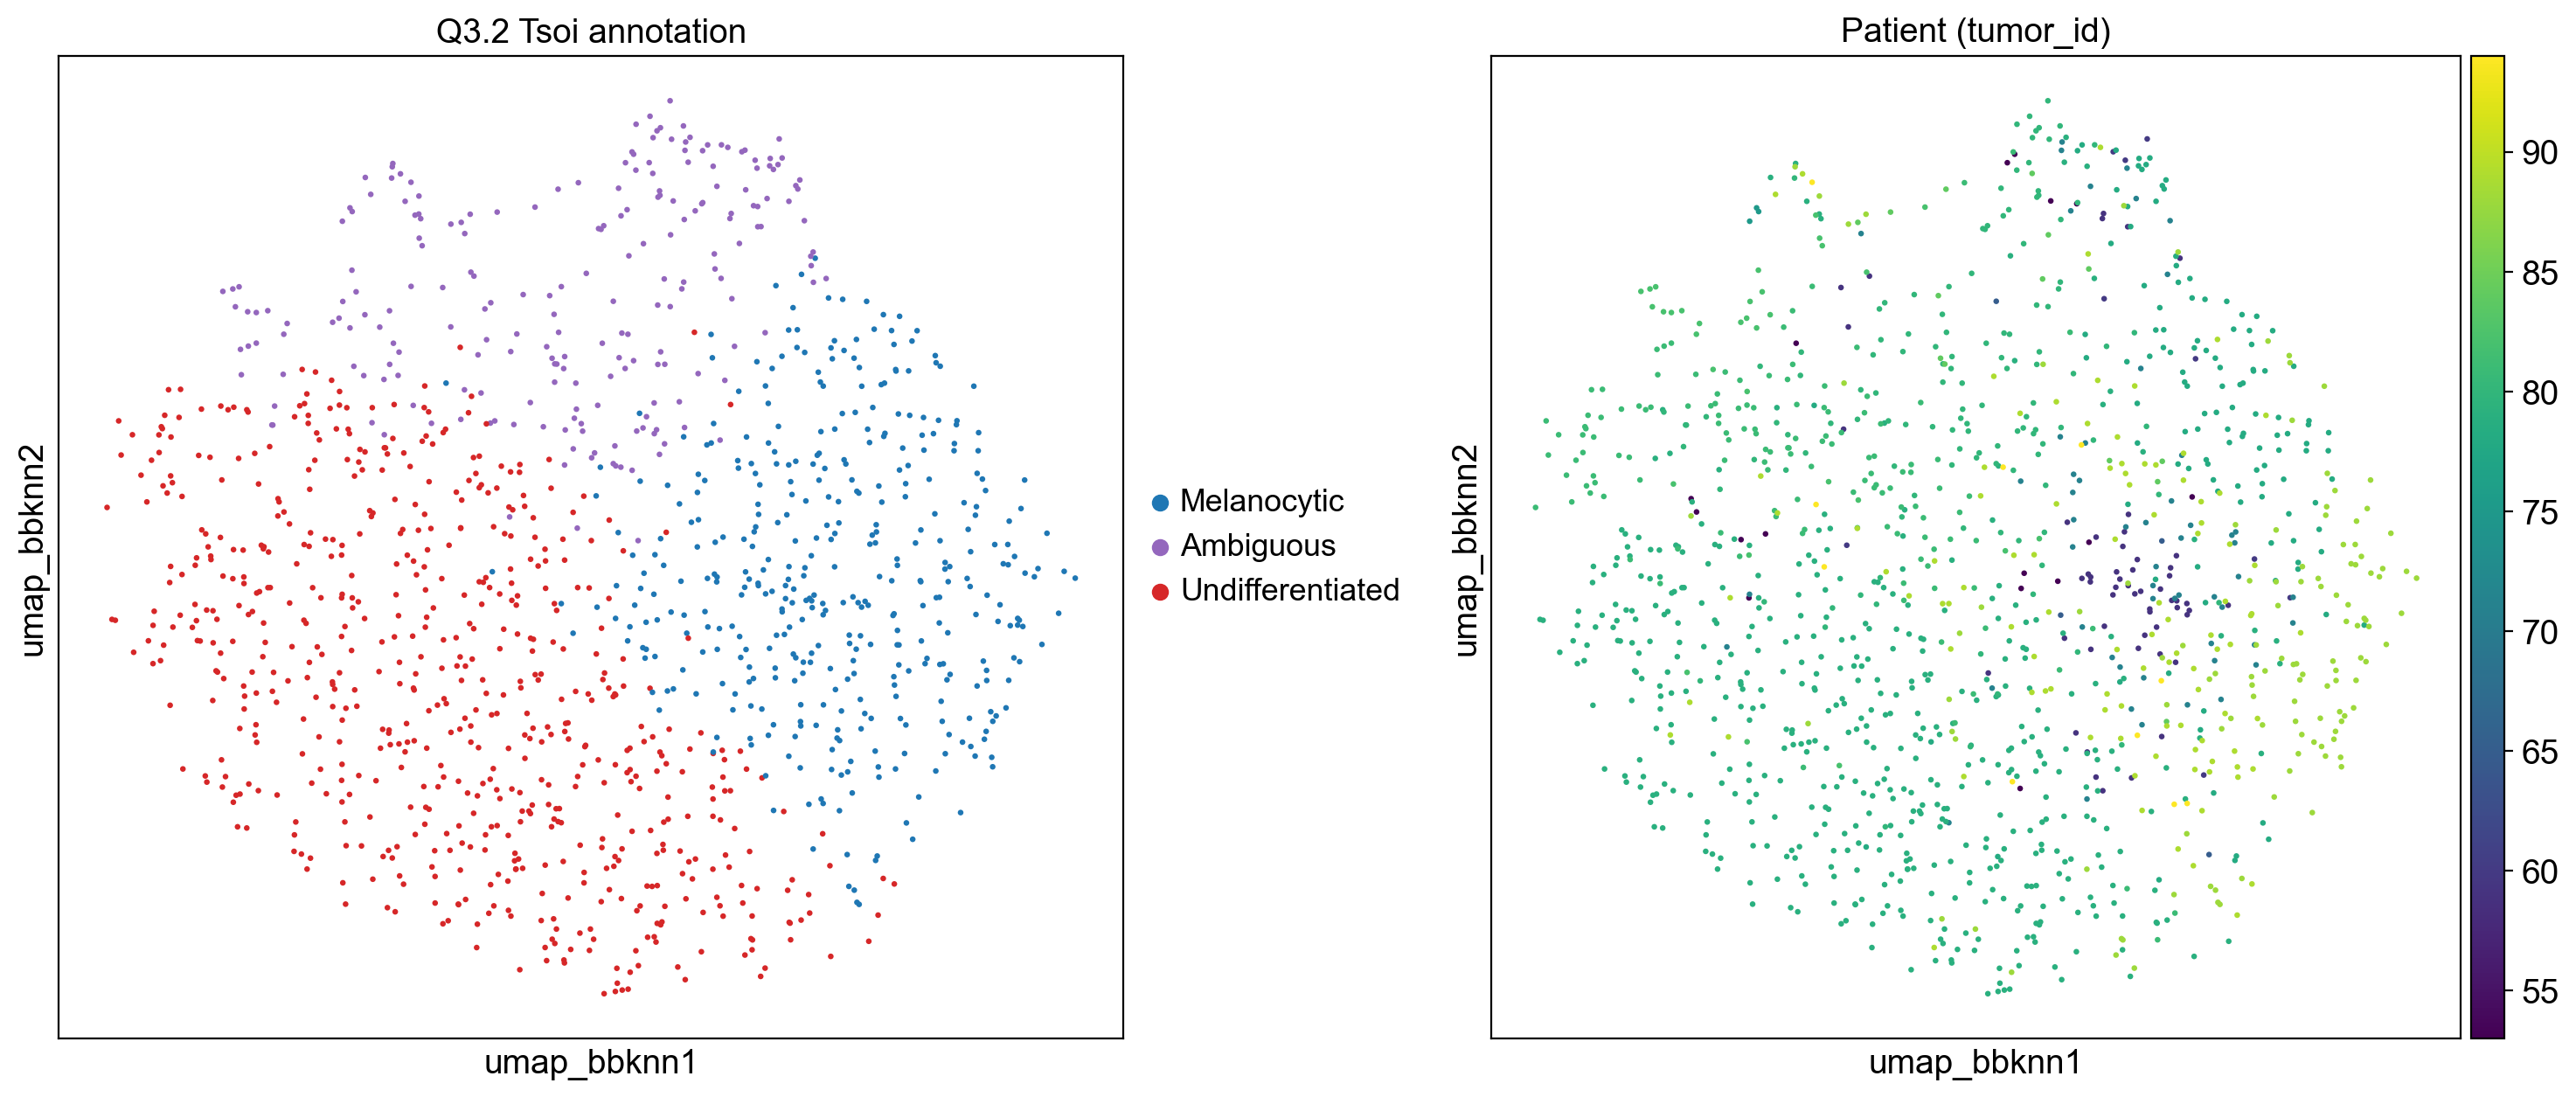

In [18]:
# 05_bbknn_final_umap_tsoi_vs_patient.png — annotation vs patient, side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc.pl.embedding(adata, basis='umap_bbknn', color='tsoi_state_bbknn',
                title='Q3.2 Tsoi annotation', ax=axes[0], show=False,
                size=22, palette=tsoi_bbknn_palette, legend_loc='right margin')
sc.pl.embedding(adata, basis='umap_bbknn', color='tumor_id',
                title='Patient (tumor_id)', ax=axes[1], show=False,
                size=22, legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_final_umap_tsoi_vs_patient.png',
            dpi=150, bbox_inches='tight')
plt.show()


saved: results/figures/05_bbknn_final_dotplot.png


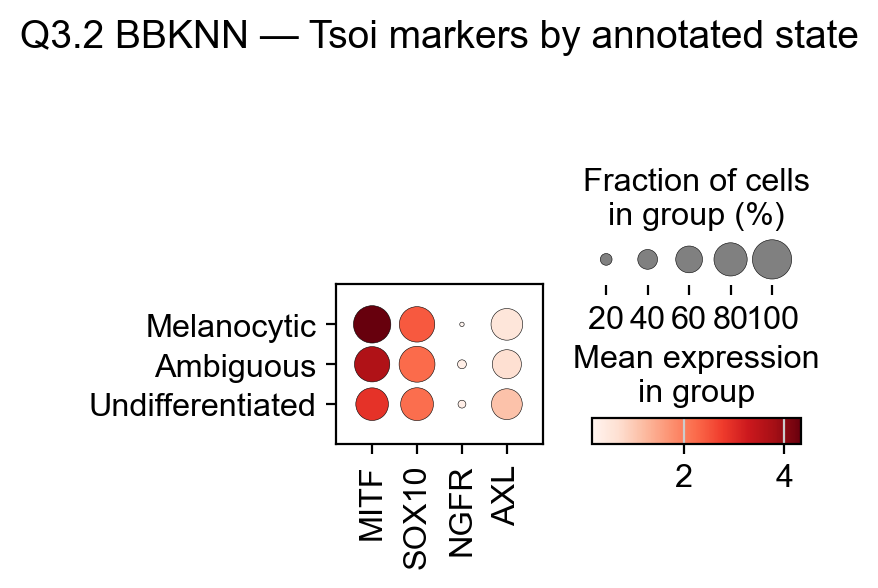

In [19]:
# 05_bbknn_final_dotplot.png — Tsoi markers grouped by annotated state
# categories_order forces the dedifferentiation sequence Mel -> Amb -> Undiff.
dp = sc.pl.dotplot(
    adata, var_names=['MITF', 'SOX10', 'NGFR', 'AXL'],
    groupby='tsoi_state_bbknn',
    categories_order=['Melanocytic', 'Ambiguous', 'Undifferentiated'],
    title='Q3.2 BBKNN — Tsoi markers by annotated state',
    show=False, return_fig=True,
)
dp.savefig('results/figures/05_bbknn_final_dotplot.png', dpi=150)
print("saved: results/figures/05_bbknn_final_dotplot.png")


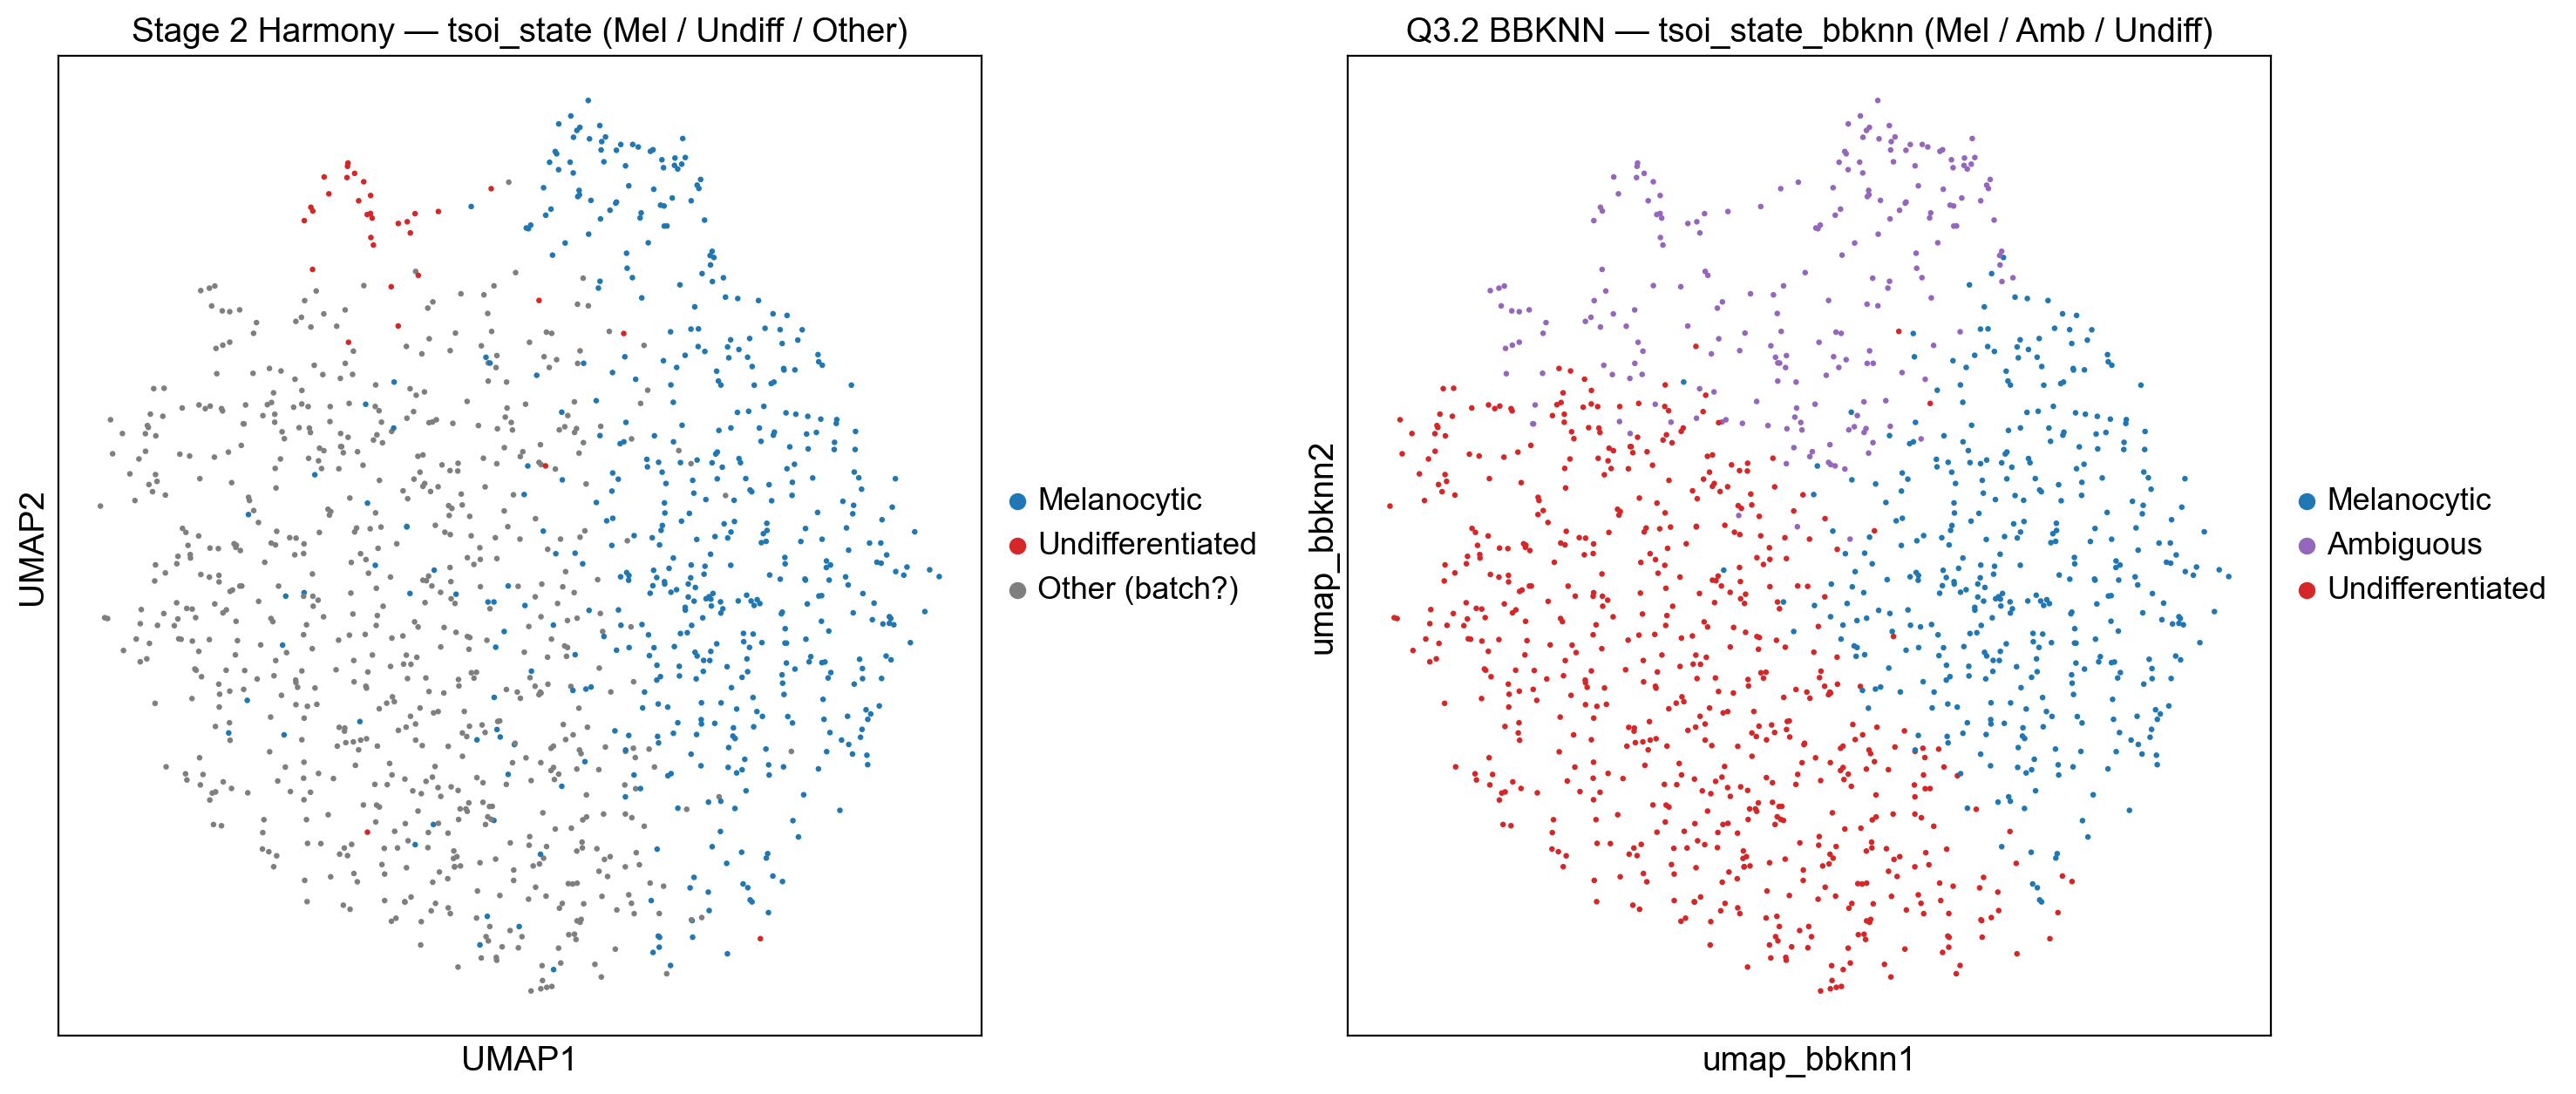

In [20]:
# 05_bbknn_final_vs_stage2_tsoi.png — final annotations side by side
# Left:  Stage 2 Harmony UMAP, colored by Stage 2 tsoi_state (Mel / Undiff / Other)
# Right: Q3.2 BBKNN UMAP, colored by Q3.2 tsoi_state_bbknn (Mel / Amb / Undiff)
# Direct visual comparison of the two methods' FINAL cell-state annotations.
stage2_palette = {
    'Melanocytic':      '#1f77b4',  # blue  — shared with Q3.2
    'Undifferentiated': '#d62728',  # red   — shared with Q3.2
    'Other (batch?)':   '#7f7f7f',  # grey  — Stage 2's batch-artifact class
}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc.pl.embedding(adata, basis='umap', color='tsoi_state',
                title='Stage 2 Harmony — tsoi_state (Mel / Undiff / Other)',
                ax=axes[0], show=False, size=22, palette=stage2_palette,
                legend_loc='right margin')
sc.pl.embedding(adata, basis='umap_bbknn', color='tsoi_state_bbknn',
                title='Q3.2 BBKNN — tsoi_state_bbknn (Mel / Amb / Undiff)',
                ax=axes[1], show=False, size=22, palette=tsoi_bbknn_palette,
                legend_loc='right margin')
plt.tight_layout()
plt.savefig('results/figures/05_bbknn_final_vs_stage2_tsoi.png',
            dpi=150, bbox_inches='tight')
plt.show()


In [21]:
# Step 10: export BBKNN-augmented AnnData (final)
# Preserves all Stage 2 carry-over metadata plus the new BBKNN artifacts:
#   - obs:  leiden_bbknn_r0.1 ... r0.8, tsoi_state_bbknn
#   - obsm: X_umap_bbknn, plus original Stage 2 keys
#   - obsp: BBKNN-corrected distances + connectivities (approx=False)
#   - uns:  neighbors (BBKNN params)
out_path = 'data/processed/tirosh_malignant_bbknn.h5ad'
adata.write_h5ad(out_path)

# Verify round-trip
verify = sc.read_h5ad(out_path)
new_obs_cols = [c for c in verify.obs.columns if 'bbknn' in c]
assert 'tsoi_state_bbknn' in verify.obs.columns, "tsoi_state_bbknn not saved!"
assert 'tsoi_state' in verify.obs.columns, "Stage 2 tsoi_state lost!"
print(f"Saved: {out_path}")
print(f"  shape:        {verify.shape}")
print(f"  obs[bbknn]:   {new_obs_cols}")
print(f"  tsoi_state_bbknn counts: "
      f"{verify.obs['tsoi_state_bbknn'].value_counts().to_dict()}")
print(f"  Stage 2 tsoi_state preserved: "
      f"{list(verify.obs['tsoi_state'].cat.categories)}")
print(f"  obsm keys:    {list(verify.obsm.keys())}")
print(f"  obsp keys:    {list(verify.obsp.keys())}")


Saved: data/processed/tirosh_malignant_bbknn.h5ad
  shape:        (1257, 23686)
  obs[bbknn]:   ['leiden_bbknn_r0.1', 'leiden_bbknn_r0.2', 'leiden_bbknn_r0.3', 'leiden_bbknn_r0.5', 'leiden_bbknn_r0.8', 'tsoi_state_bbknn']
  tsoi_state_bbknn counts: {'Undifferentiated': 635, 'Melanocytic': 404, 'Ambiguous': 218}
  Stage 2 tsoi_state preserved: ['Melanocytic', 'Undifferentiated', 'Other (batch?)']
  obsm keys:    ['X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_bbknn', 'X_umap_uncorrected']
  obsp keys:    ['connectivities', 'distances']


## Annotation Decisions (Q3.2 BBKNN, res=0.5, approx=False)

### Cluster 0 → Melanocytic
MITF 4.33 (94%) — highest among all clusters. SOX10 2.42 (87%) co-expressed.
NGFR essentially silent (5%). AXL 0.53 (75%) — lowest among all clusters;
broad expression but low magnitude. Cross-patient support (pt78 24%, ✓ multi-pt).
This matches the canonical Tsoi Melanocytic signature: MITF↑ SOX10↑ NGFR↓ AXL↓.

### Cluster 1 → Undifferentiated (medium confidence, with caveats)
MITF 2.90 (78%) — lowest among all clusters. AXL 1.10 (72%) — highest among all
clusters. This is the dedifferentiation axis's "low-differentiation end":
MITF↓ AXL↑ matches the core Tsoi Undifferentiated signature.

**Caveat 1 — SOX10**: SOX10 here is 2.18 (79%), medium rather than low. The strict
Tsoi Undifferentiated definition also requires SOX10↓; SOX10 loss is the latest
event — it marks the most extreme terminal Undifferentiated state. The modest
SOX10 downregulation here suggests that Tirosh's malignant cells sampled the
Melanocytic→Undifferentiated trajectory but did not reach the SOX10-low terminus.
Cluster 1 is the most dedifferentiated population present in the data, but it
represents the "dedifferentiated end of the trajectory" rather than a pure
terminal Undifferentiated state.

**Caveat 2 — pt79 dominance**: pt79 contributes 68% of this cluster (◐ skew).
This is below the strict 70% batch-artifact threshold, and the remaining 32%
comes from other patients with the same marker pattern. The biological
interpretation is that pt79 is enriched for Undifferentiated-tendency cells,
not that this cluster is a pure batch artifact. Cross-method evidence supports
this: Stage 2 Harmony identified pt79 as its own batch-pure cluster (cluster 5,
99.8% pt79 — 417 of 418 cells), but Q3.2 BBKNN with approx=False integrated pt79 cells with other
patients sharing the same Undifferentiated marker pattern, suggesting the
Harmony-era "pt79 batch" was a methodological under-correction rather than a
true patient-specific phenomenon.

### Cluster 2 → Ambiguous
MITF 3.65 (87%), SOX10 2.24 (89%), NGFR 0.33 (14%), AXL 0.68 (67%) — all markers
medium, none at canonical extremes. Cross-patient (pt80 44%, ✓ multi-pt).
Located between Cluster 0 (Melanocytic) and Cluster 1 (Undifferentiated) on the
MITF/AXL gradient. The Tsoi intermediate states (Transitory, Neural crest-like)
both require NGFR↑, but Cluster 2's NGFR (14%) does not meet this threshold.
Without a defining marker for either intermediate state, this cluster is
labeled Ambiguous rather than forced into a Tsoi category.

### Methodological notes

**Why res=0.5 over alternatives**: res=0.1/0.2 yielded only 1 cluster
(over-merging). res=0.3 yielded 2 clusters (lost the Undifferentiated/Ambiguous
distinction). res=0.8 yielded 6 clusters under approx=False; the additional
clusters mostly represent finer subdivision of Melanocytic and Undifferentiated
regions rather than recovery of new Tsoi states. A small cluster (n=19) at
res=0.8 initially appeared to have elevated NGFR expression (a possible neural
crest-like state). However, cell-level investigation revealed the signal was
driven by 4 outlier cells from a single patient (pt53), with no supporting
expression of other neural crest-like markers (PAX3 was lowest in this cluster;
SOX2 and GFRA1 were absent). This illustrates how aggregate cluster statistics
can create the appearance of biological signal where none robustly exists at
single-cell level. res=0.5's 3-cluster partition is therefore the coarsest
resolution that retains the Melanocytic/Ambiguous/Undifferentiated structure
without introducing redundant or outlier-driven subclusters.

**Why approx=False matters**: BBKNN with default approximate nearest neighbors
gave a 4-cluster partition with 2 batch-pure clusters (pt79 98% and pt59 98%).
Exact nearest neighbors (approx=False) produced a 3-cluster partition where
these patients were integrated with biologically-similar cells from other
patients. The approx-vs-exact difference reveals that some apparent "batch
artifacts" in approximate runs were actually integration failures, not true
patient-specific biology. This finding informs the reproducibility section.
